BƯỚC 1: IMPORT CÁC THƯ VIỆN QUAN TRỌNG

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

BƯỚC 2: ĐỌC DỮ LIỆU COMMENT ĐÃ XỬ LÝ CỦA PHIM AVATAR

In [3]:
df = pd.read_csv("youtube_trailer_comments_cleaned.csv")

df.head()

,comment,clean_text,tokens,tokens_nostop,comment_length,sentiment_score,sentiment_label,word_count
0,Jake has master Earth and Water. Now he needs ...,jake has master earth and water now he needs t...,"['jake', 'has', 'master', 'earth', 'and', 'wat...","['jake', 'master', 'earth', 'water', 'needs', ...",95,0.1027,Positive,19
1,"I was single when the first movie came out, I ...",i was single when the first movie came out i w...,"['i', 'was', 'single', 'when', 'the', 'first',...","['single', 'first', 'movie', 'came', 'single',...",139,0.0000,Neutral,28
2,"I finished school, went to university, found a...",i finished school went to university found a j...,"['i', 'finished', 'school', 'went', 'to', 'uni...","['finished', 'school', 'went', 'university', '...",111,0.0000,Neutral,20
3,"The whole Avatar series, I think, James Camero...",the whole avatar series i think james cameron ...,"['the', 'whole', 'avatar', 'series', 'i', 'thi...","['whole', 'avatar', 'series', 'think', 'james'...",117,0.3818,Positive,19
4,At least we didn’t have to wait another decade...,at least we didnt have to wait another decade ...,"['at', 'least', 'we', 'didnt', 'have', 'to', '...","['least', 'didnt', 'wait', 'another', 'decade']",55,0.0000,Neutral,11


BƯỚC 3: KIỂM TRA VÀ CHUẨN BỊ DỮ LIỆU

In [4]:
# Giữ các cột cần thiết
df = df[["clean_text", "sentiment_label"]]
# Loại bỏ NaN
df = df.dropna()
# Ép kiểu string cho text
df["clean_text"] = df["clean_text"].astype(str)
df["sentiment_label"].value_counts()

sentiment_label
Positive    219
Neutral     111
Negative     87
Name: count, dtype: int64

BƯỚC 4: TÁCH X, y & ENCODE NHÃN

In [5]:
X = df["clean_text"]
y = df["sentiment_label"]
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
print("Label mapping:")
for i, label in enumerate(label_encoder.classes_):
    print(i, "→", label)

Label mapping:
0 → Negative
1 → Neutral
2 → Positive


BƯỚC 5: CHIA TẬP TRAIN, TEST

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.3,
    random_state=42,
    stratify=y_encoded
)

BƯỚC 6 VECTO HÓA

In [7]:
vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=5000
)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

BƯỚC 7: TRAIN MODEL (LOGISTIC REGRESSION – MULTICLASS)

In [8]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_vec, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
#Lưu mô hình logistic regression để ứng dụng
import joblib
# Lưu mô hình ML
joblib.dump(model, "sentiment.mdl")
# Lưu vectorizer
joblib.dump(vectorizer, "vectorizer.pkl")
# Lưu label encoder
joblib.dump(label_encoder, "label_encoder.pkl")
print("Đã lưu xong model, vectorizer và label encoder")

Đã lưu xong model, vectorizer và label encoder


BƯỚC 8: ĐÁNH GIÁ MÔ HÌNH

In [10]:
y_pred = model.predict(X_test_vec)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.6825396825396826


In [11]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

    Negative       0.62      0.38      0.48        26
     Neutral       0.60      0.74      0.66        34
    Positive       0.75      0.77      0.76        66

    accuracy                           0.68       126
   macro avg       0.66      0.63      0.63       126
weighted avg       0.68      0.68      0.67       126



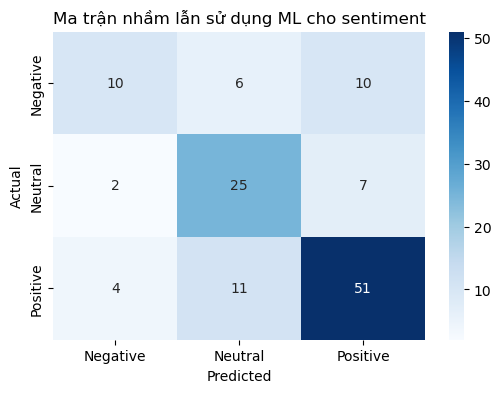

In [12]:
#Sử dụng ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Ma trận nhầm lẫn sử dụng ML cho sentiment")
plt.show()

SỬ DỤNG SVM

In [13]:
from sklearn.svm import LinearSVC

model = LinearSVC(class_weight='balanced')
model.fit(X_train_vec, y_train)

LinearSVC(class_weight='balanced')

In [16]:
# Dự đoán trên tập test
y_pred_svm = model.predict(X_test_vec)

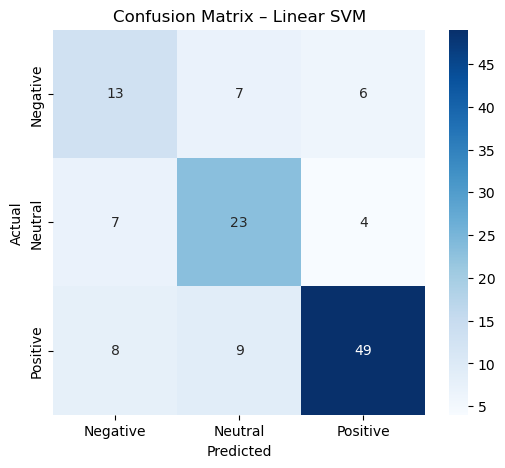

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Linear SVM")
plt.show()

In [18]:
from sklearn.metrics import accuracy_score

accuracy_svm = accuracy_score(y_test, y_pred_svm)
print("Accuracy của Linear SVM:", accuracy_svm)

Accuracy của Linear SVM: 0.6746031746031746
